In [3]:
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.float_format', '{:.6f}'.format)

In [4]:
votes = pd.read_parquet("../../data/raw/votes.parquet")
conv = pd.read_parquet("../../data/raw/conversations.parquet")
reactions = pd.read_parquet("../../data/raw/reactions.parquet")

In [5]:
# Mettre les deux modèles dans la même colonne
a = conv[["model_a_name","total_conv_a_kwh"]].rename(columns={"model_a_name":"model","total_conv_a_kwh":"kwh"})
b = conv[["model_b_name","total_conv_b_kwh"]].rename(columns={"model_b_name":"model","total_conv_b_kwh":"kwh"})
print(pd.concat([a,b]).groupby("model")["kwh"].mean().sort_values(ascending=False))


model
grok-4.20                       0.132245
qwen3.6-plus                    0.027252
glm-5.1                         0.010539
gemini-3.1-pro-preview          0.010219
glm-5                           0.009999
kimi-k2.6                       0.009006
kimi-k2.5                       0.008211
mistral-large-2512              0.008110
claude-4-6-sonnet               0.008103
deepseek-r1-0528                0.006527
kimi-k2-thinking                0.005907
claude-4-5-sonnet               0.005755
qwen3.5-397b-a17b               0.004927
gpt-5.4                         0.004793
glm-4.7                         0.004756
grok-4.1-fast                   0.004473
DeepSeek-V3.2                   0.003921
qwen3-max-2025-09-23            0.003828
gemini-3-flash-preview          0.003711
kimi-k2                         0.002757
minimax-m2.7                    0.001861
mistral-medium-2508             0.001500
gpt-5.3                         0.001491
minimax-m2                      0.001088
minimax-m2

In [6]:
# On met model_a et model_b dans la même colonne pour pouvoir grouper
side_a = conv[["model_a_name", "total_conv_a_kwh"]].rename(
    columns={"model_a_name": "model", "total_conv_a_kwh": "kwh"}
)
side_b = conv[["model_b_name", "total_conv_b_kwh"]].rename(
    columns={"model_b_name": "model", "total_conv_b_kwh": "kwh"}
)

energy = (
    pd.concat([side_a, side_b])
    .groupby("model")["kwh"]
    .mean()
    .rename("avg_kwh")
    .reset_index()
)

energy = energy.sort_values("avg_kwh", ascending=False).reset_index(drop=True)
energy[energy["avg_kwh"] > 0.00001]

,model,avg_kwh
0,grok-4.20,0.132245
1,qwen3.6-plus,0.027252
2,glm-5.1,0.010539
3,gemini-3.1-pro-preview,0.010219
4,glm-5,0.009999
5,kimi-k2.6,0.009006
6,kimi-k2.5,0.008211
7,mistral-large-2512,0.008110
8,claude-4-6-sonnet,0.008103
9,deepseek-r1-0528,0.006527


In [7]:
side_a = conv[["model_a_name", "total_conv_a_kwh"]].rename(
    columns={"model_a_name": "model", "total_conv_a_kwh": "kwh"}
)
side_b = conv[["model_b_name", "total_conv_b_kwh"]].rename(
    columns={"model_b_name": "model", "total_conv_b_kwh": "kwh"}
)

energy_full = (
    pd.concat([side_a, side_b])
    .groupby("model")
    .agg(
        avg_kwh=("kwh", "mean"),
        nb_conversations=("kwh", "count")
    )
    .reset_index()
)

SEUIL_MIN = 200
exclus_df = energy_full[energy_full["nb_conversations"] < SEUIL_MIN][["model", "nb_conversations"]]
exclus_str = ", ".join(f"{row['model']} ({row['nb_conversations']} conv.)" for _, row in exclus_df.iterrows())
print(f"{len(exclus_df)} modèles exclus (< {SEUIL_MIN} conversations) : {exclus_str}")

energy = (
    energy_full[energy_full["nb_conversations"] >= SEUIL_MIN]
    .sort_values("avg_kwh", ascending=False)
    .reset_index(drop=True)
)

energy.index += 1
energy.index.name = "rang"

energy.head(15).style.format({
    "avg_kwh": "{:.5f}",
    "nb_conversations": "{:,.0f}"
})


7 modèles exclus (< 200 conversations) : glm-5.1 (83 conv.), grok-4.20 (53 conv.), kimi-k2.6 (79 conv.), lfm2-24b-a2b (104 conv.), lfm2-8b-a1b (47 conv.), minimax-m2.7 (74 conv.), qwen3.6-plus (70 conv.)


,model,avg_kwh,nb_conversations
rang,,,
1,gemini-3.1-pro-preview,0.01022,"1,273"
2,glm-5,0.01000,591
3,kimi-k2.5,0.00821,655
4,mistral-large-2512,0.00811,"1,023"
5,claude-4-6-sonnet,0.00810,"1,505"
6,deepseek-r1-0528,0.00653,736
7,kimi-k2-thinking,0.00591,525
8,claude-4-5-sonnet,0.00576,927
9,qwen3.5-397b-a17b,0.00493,653


In [8]:
# kWh par token de sortie
# On divise le total d'énergie par le total de tokens générés par modèle
# (somme/somme plutôt que moyenne des ratios — plus robuste statistiquement)
# les valeurs affichées sont en milliwattheures par token pour plus de visibilité

side_a_tok = conv[['model_a_name', 'total_conv_a_kwh', 'total_conv_a_output_tokens']].rename(
    columns={'model_a_name': 'model', 'total_conv_a_kwh': 'kwh', 'total_conv_a_output_tokens': 'tokens'}
)
side_b_tok = conv[['model_b_name', 'total_conv_b_kwh', 'total_conv_b_output_tokens']].rename(
    columns={'model_b_name': 'model', 'total_conv_b_kwh': 'kwh', 'total_conv_b_output_tokens': 'tokens'}
)

efficiency = (
    pd.concat([side_a_tok, side_b_tok])
    .groupby('model')
    .agg(total_kwh=('kwh', 'sum'), total_tokens=('tokens', 'sum'), nb_conversations=('kwh', 'count'))
    .query('nb_conversations >= 200')
    .assign(kwh_per_token=lambda df: df['total_kwh'] / df['total_tokens'])
    .assign(mwh_per_token=lambda df: df['kwh_per_token'] * 1_000_000)
    .reset_index()
    .sort_values('kwh_per_token')
)

efficiency[['model', 'mwh_per_token', 'total_tokens', 'nb_conversations']].head(20).style.format({
    'mwh_per_token': '{:.6f}',
    'total_tokens': '{:,.0f}',
    'nb_conversations': '{:,.0f}'
})

,model,mwh_per_token,total_tokens,nb_conversations
22,gpt-oss-20b,0.083086,"1,584,241","1,078"
13,gemma-4-26b-a4b-it,0.084299,"636,027",688
12,gemma-3n-e4b-it,0.084299,"561,925",682
20,gpt-5.4-nano,0.084299,"733,524",791
11,gemma-3-4b,0.084299,"616,419",657
9,gemma-3-12b,0.094006,"721,344",683
2,EuroLLM-22B-Instruct-2512,0.106140,"395,224",713
35,mistral-small-2506,0.108567,"546,830",822
10,gemma-3-27b,0.112207,"612,092",630
14,gemma-4-31b-it,0.117060,"524,050",790


In [9]:
efficiency.sort_values("mwh_per_token", ascending=False).head(15)

,model,total_kwh,total_tokens,nb_conversations,kwh_per_token,mwh_per_token
23,grok-4.1-fast,12.765689,881551,2854,0.000014,14.480942
8,gemini-3.1-pro-preview,13.008290,3032570,1273,0.000004,4.289527
33,mistral-large-2512,8.296660,2006829,1023,0.000004,4.134214
16,glm-5,5.909424,1442947,591,0.000004,4.095386
1,DeepSeek-V3.2,3.242534,814932,827,0.000004,3.978901
5,deepseek-r1-0528,4.803624,1207274,736,0.000004,3.978901
6,gemini-3-flash-preview,3.076457,782642,829,0.000004,3.930861
3,claude-4-5-sonnet,5.335189,1357257,927,0.000004,3.930861
4,claude-4-6-sonnet,12.195037,3102383,1505,0.000004,3.930861
25,kimi-k2,1.491528,394088,541,0.000004,3.784760


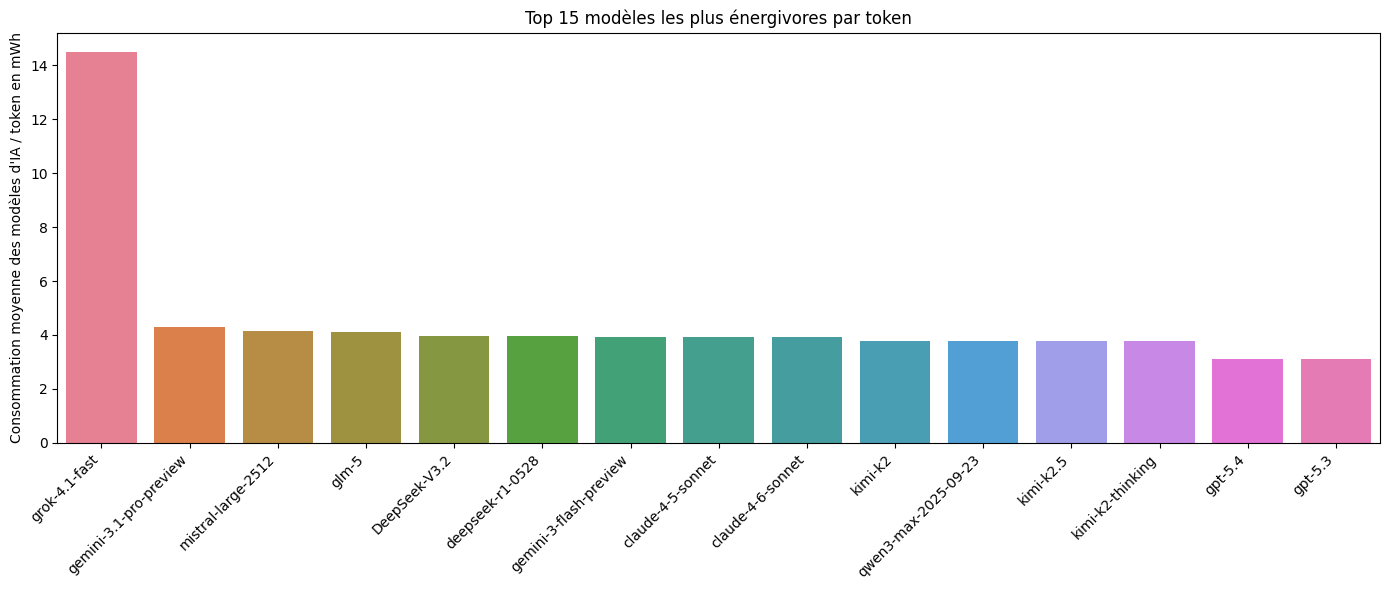

In [10]:
# bar plot des résultats de consommation par tokens

top_tok = efficiency.sort_values("mwh_per_token", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(14,6))

sns.barplot(data=top_tok, x="model", y="mwh_per_token", hue="model", ax=ax)

ax.set_xlabel("")
ax.set_ylabel("Consommation moyenne des modèles d'IA / token en mWh")
ax.set_title("Top 15 modèles les plus énergivores par token")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")

plt.tight_layout()
plt.show()

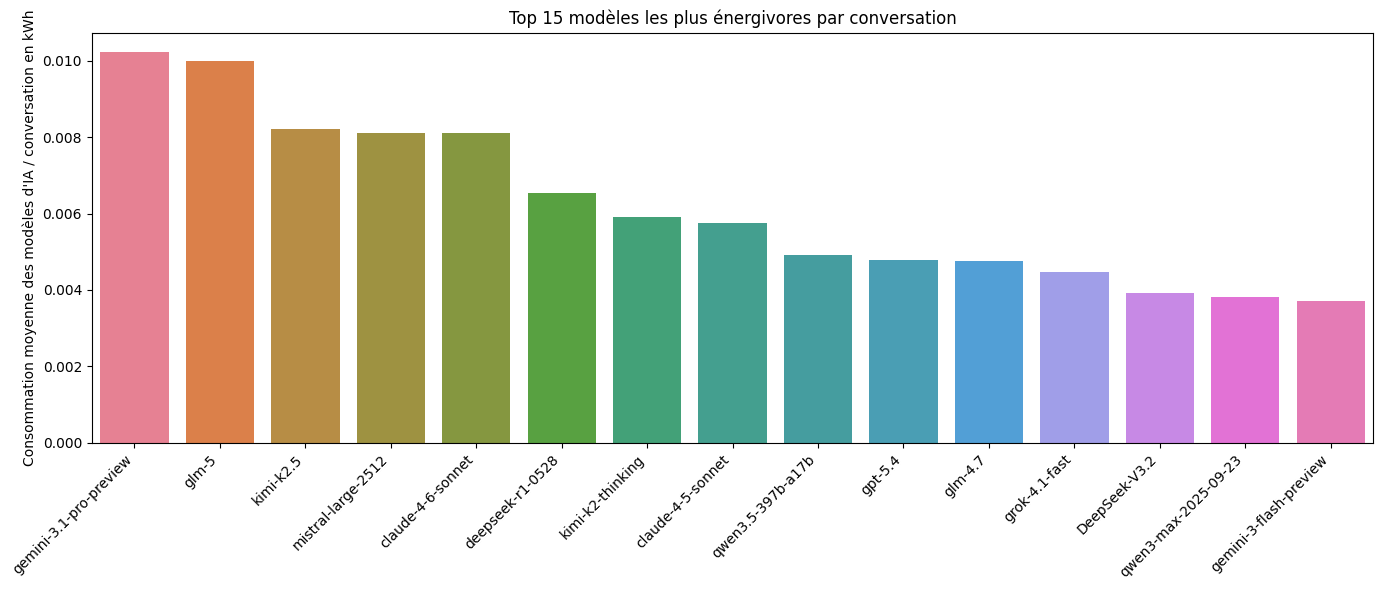

In [11]:
# bar plot des résultats de consommation par conversation

top = energy.sort_values("avg_kwh", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(14,6))

sns.barplot(data=top, x="model", y="avg_kwh", hue="model", ax=ax)

ax.set_xlabel("")
ax.set_ylabel("Consommation moyenne des modèles d'IA / conversation en kWh")
ax.set_title("Top 15 modèles les plus énergivores par conversation")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")

plt.tight_layout()
plt.show()

In [12]:
votes["both_equal"].value_counts()

both_equal
False    86300
True     44453
Name: count, dtype: int64

# 33%
des duels finissent en égalité, ce n'est pas négligeable, on va donc introduire une autre manière de calculer le taux de victoire, par un système de score

In [13]:
# Classement des modèles par score ajusté :
# victoire = 1 pt, égalité = 0.5 pt, défaite = 0 pt
# Les égalités sont réparties équitablement entre les deux modèles du duel

ties = votes[votes["both_equal"].eq(True)]
wins = votes[votes["both_equal"].eq(False)]

points = wins["chosen_model_name"].value_counts().rename("points")

ties_a = ties["model_a_name"].value_counts() * 0.5
ties_b = ties["model_b_name"].value_counts() * 0.5
points = points.add(ties_a, fill_value=0).add(ties_b, fill_value=0)

duels = (
    votes["model_a_name"].value_counts()
    .add(votes["model_b_name"].value_counts(), fill_value=0)
    .rename("duels")
)

classement_score_ajuste = (
    pd.DataFrame({"points": points, "duels": duels})
    .dropna()
    .assign(score=lambda df: df["points"] / df["duels"] * 100)
    .query("duels >= 200")
    .sort_values("score", ascending=False)
    .reset_index()
    .rename(columns={"index": "model"})
)

print(f"{len(classement_score_ajuste)} modèles retenus")
classement_score_ajuste.head(50)

104 modèles retenus


,model,points,duels,score
0,gemini-2.0-flash,4130.000000,6386,64.672722
1,deepseek-v3-chat,2309.000000,3605,64.049931
2,deepseek-v3-0324,2089.500000,3418,61.132241
3,mistral-medium-2508,2918.500000,4832,60.399421
4,gemini-3-flash-preview,1231.500000,2078,59.263715
5,gemini-2.5-flash,1704.000000,2885,59.064125
6,mistral-small-2603,370.500000,631,58.716323
7,gemini-3.1-flash-lite-preview,615.500000,1052,58.507605
8,mistral-large-2512,1989.000000,3412,58.294256
9,gemma-3-27b,3955.500000,6824,57.964537


In [14]:
# Intervalle de confiance à 95% sur le score ajusté
# Formule : IC = 1.96 * sqrt(p * (1-p) / n)
# p = proportion (score / 100), n = nombre de duels

z = 1.96  # seuil pour un IC à 95%

classement_score_ajuste = classement_score_ajuste.assign(
    p=lambda df: df["score"] / 100,
    ic=lambda df: z * (df["p"] * (1 - df["p"]) / df["duels"]) ** 0.5 * 100,
    score_min=lambda df: df["score"] - df["ic"],
    score_max=lambda df: df["score"] + df["ic"],
).drop(columns="p")

classement_score_ajuste.head(20)

,model,points,duels,score,ic,score_min,score_max
0,gemini-2.0-flash,4130.000000,6386,64.672722,1.172350,63.500372,65.845072
1,deepseek-v3-chat,2309.000000,3605,64.049931,1.566436,62.483495,65.616367
2,deepseek-v3-0324,2089.500000,3418,61.132241,1.634180,59.498061,62.766421
3,mistral-medium-2508,2918.500000,4832,60.399421,1.378986,59.020435,61.778406
4,gemini-3-flash-preview,1231.500000,2078,59.263715,2.112606,57.151109,61.376321
5,gemini-2.5-flash,1704.000000,2885,59.064125,1.794308,57.269816,60.858433
6,mistral-small-2603,370.500000,631,58.716323,3.841581,54.874742,62.557904
7,gemini-3.1-flash-lite-preview,615.500000,1052,58.507605,2.977410,55.530195,61.485014
8,mistral-large-2512,1989.000000,3412,58.294256,1.654483,56.639772,59.948739
9,gemma-3-27b,3955.500000,6824,57.964537,1.171185,56.793351,59.135722


In [15]:
import os

def export_df(df):
    output_dir = "../../data/processed"
    filename = "dataframe_inconnu.csv"
    for nom_variable, valeur in globals().items():
        if valeur is df and isinstance(valeur, pd.DataFrame):
            filename = f"{nom_variable}.csv"
            break
    os.makedirs(output_dir, exist_ok=True)
    filepath = os.path.join(output_dir, filename)
    df.to_csv(filepath, index=False)
    print(f"Exporté : {filepath} ({len(df)} lignes)")

export_df(energy)

Exporté : ../../data/processed/energy.csv (44 lignes)


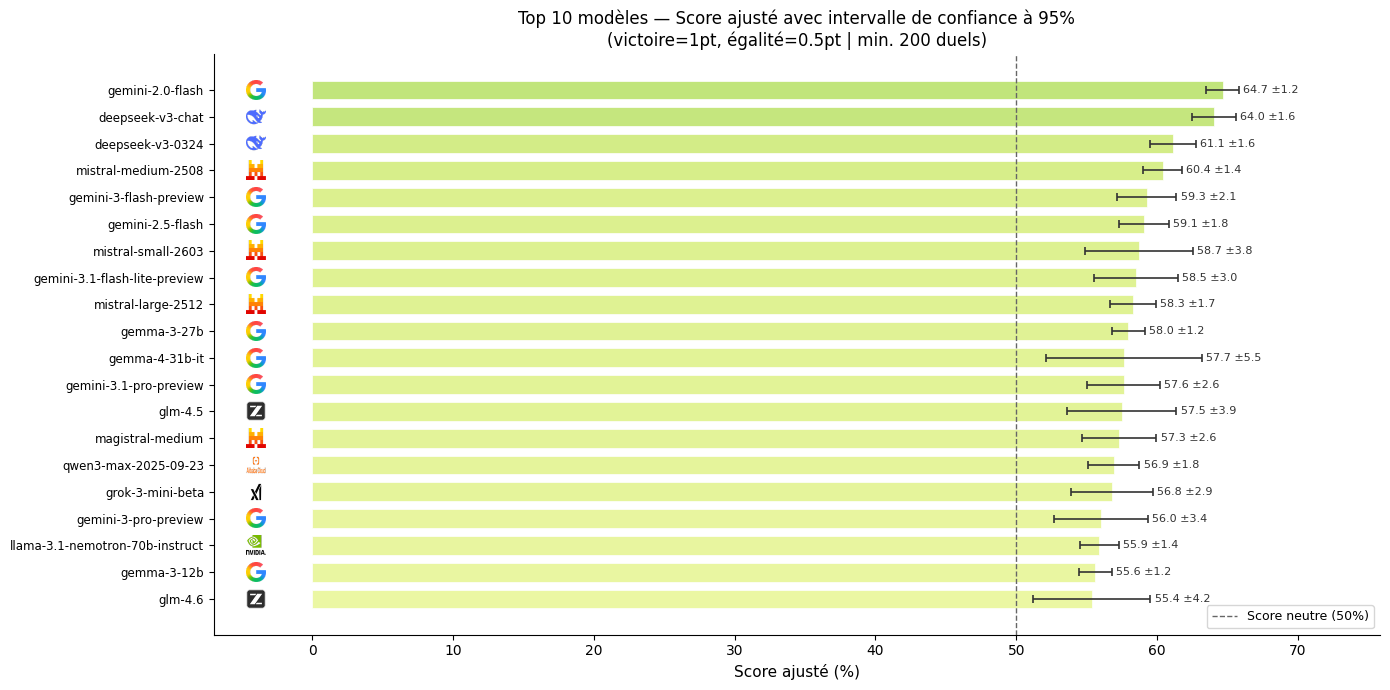

In [16]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import urllib.request
from PIL import Image
import io
import numpy as np

df_plot = classement_score_ajuste.head(20).iloc[::-1]

def get_provider(model):
    if model.startswith(('gemini', 'gemma')):
        return 'google'
    elif model.startswith('deepseek'):
        return 'deepseek'
    elif model.startswith('mistral'):
        return 'mistral'
    elif model.startswith('magistral'):
        return 'mistral'
    elif model.startswith('grok'):
        return 'xai'
    elif 'nemotron' in model:
        return 'nvidia'
    elif model.startswith('glm'):
        return 'zhipu'
    elif model.startswith('qwen'):
        return 'qwen'
    return None

logo_urls = {
    'google':   'https://upload.wikimedia.org/wikipedia/commons/thumb/3/3c/Google_Favicon_2025.svg/250px-Google_Favicon_2025.svg.png',
    'deepseek': 'https://raw.githubusercontent.com/lobehub/lobe-icons/refs/heads/master/packages/static-png/dark/deepseek-color.png',
    'mistral':  'https://mistral.ai/_next/image?url=%2Fstatic%2Fbranding%2Fm%2Fm-rainbow.png&w=828&q=75&dpl=19be83239a61103e4c78652cf3efdb94fd221c399ace118c15bc615d6cf222cb366131313764623631323634363136306365376330383638',
    'zhipu': 'https://upload.wikimedia.org/wikipedia/commons/thumb/f/f4/Z.ai_%28company_logo%29.svg/250px-Z.ai_%28company_logo%29.svg.png',
    'qwen':  'https://ik.imagekit.io/businesswith/tr:w-200,h-100,cm-pad_resize,dpr-2/logo/alibaba-cloud-logo.png',
    'xai':   'https://upload.wikimedia.org/wikipedia/commons/thumb/9/93/XAI_Logo.svg/3840px-XAI_Logo.svg.png',
    'nvidia': 'https://upload.wikimedia.org/wikipedia/sco/thumb/2/21/Nvidia_logo.svg/3840px-Nvidia_logo.svg.png',
}

logo_imgs = {}
for name, url in logo_urls.items():
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=10) as r:
            img = Image.open(io.BytesIO(r.read())).convert('RGBA').resize((40, 40), Image.LANCZOS)
            logo_imgs[name] = np.array(img)
    except Exception as e:
        print(f'Logo {name} non chargé : {e}')

fig, ax = plt.subplots(figsize=(14, 7))

colors = plt.cm.RdYlGn([x / 100 for x in df_plot['score']])

ax.barh(
    range(len(df_plot)),
    df_plot['score'],
    xerr=df_plot['ic'],
    color=colors,
    edgecolor='white',
    linewidth=0.5,
    error_kw=dict(ecolor='#333333', lw=1.2, capsize=3, capthick=1.2),
    height=0.7,
)

ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot['model'].values, fontsize=9)

ax.axvline(50, color='#666666', linestyle='--', linewidth=1, label='Score neutre (50%)')

for i, (_, row) in enumerate(df_plot.iterrows()):
    ax.text(
        row['score'] + row['ic'] + 0.3, i,
        f"{row['score']:.1f} ±{row['ic']:.1f}",
        va='center', fontsize=8, color='#333333'
    )

# Logos à gauche des barres
logo_x = -4
for i, (_, row) in enumerate(df_plot.iterrows()):
    provider = get_provider(row['model'])
    if provider in logo_imgs:
        imagebox = OffsetImage(logo_imgs[provider], zoom=0.35)
        ab = AnnotationBbox(imagebox, (logo_x, i), xycoords='data', frameon=False, pad=0)
        ax.add_artist(ab)

max_x = (df_plot['score'] + df_plot['ic']).max()
ax.set_xlim(logo_x - 3, max_x + 10)
ax.set_xticks([t for t in range(0, int(max_x) + 15, 10) if t >= 0])

ax.set_xlabel('Score ajusté (%)', fontsize=11)
ax.set_title(
    'Top 10 modèles — Score ajusté avec intervalle de confiance à 95%\n'
    '(victoire=1pt, égalité=0.5pt | min. 200 duels)',
    fontsize=12
)
ax.legend(fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='y', labelsize=8.5)
plt.tight_layout()
plt.show()


In [17]:
croise = classement_score_ajuste.merge(energy, on="model", how="inner")
croise

,model,points,duels,score,ic,score_min,score_max,avg_kwh,nb_conversations
0,mistral-medium-2508,2918.500000,4832,60.399421,1.378986,59.020435,61.778406,0.001500,698
1,gemini-3-flash-preview,1231.500000,2078,59.263715,2.112606,57.151109,61.376321,0.003711,829
2,mistral-small-2603,370.500000,631,58.716323,3.841581,54.874742,62.557904,0.000617,777
3,gemini-3.1-flash-lite-preview,615.500000,1052,58.507605,2.977410,55.530195,61.485014,0.000229,2968
4,mistral-large-2512,1989.000000,3412,58.294256,1.654483,56.639772,59.948739,0.008110,1023
5,gemma-3-27b,3955.500000,6824,57.964537,1.171185,56.793351,59.135722,0.000109,630
6,gemma-4-31b-it,177.000000,307,57.654723,5.527221,52.127502,63.181944,0.000078,790
7,gemini-3.1-pro-preview,807.500000,1401,57.637402,2.587501,55.049901,60.224903,0.010219,1273
8,qwen3-max-2025-09-23,1619.000000,2844,56.926864,1.819924,55.106940,58.746787,0.003828,590
9,gemma-3-12b,3727.500000,6701,55.626026,1.189568,54.436458,56.815594,0.000099,683


In [20]:
# Score ajusté par kWh : pour 1 kWh dépensé, combien de points de score ?
# Permet de comparer qualité et efficience énergétique ensemble

croise = croise.assign(
    score_par_kwh=lambda df: df['score'] / df['avg_kwh']
).sort_values('score_par_kwh', ascending=False)

croise[['model', 'score', 'avg_kwh', 'score_par_kwh', 'duels', 'nb_conversations']].style.format({
    'score': '{:.2f}',
    'avg_kwh': '{:.5f}',
    'score_par_kwh': '{:,.0f}',
    'nb_conversations': '{:,.0f}',
    'duels': '{:,.0f}',
})

,model,score,avg_kwh,score_par_kwh,duels,nb_conversations
43,olmo-3-32b-think,30.57,0.00000,"55,369,677",687,325
38,EuroLLM-22B-Instruct-2512,44.69,0.00006,"759,643","1,027",713
6,gemma-4-31b-it,57.65,0.00008,"742,471",307,790
15,mistral-small-2506,51.93,0.00007,"719,018","4,819",822
24,gemma-3n-e4b-it,49.79,0.00007,"716,774","4,187",682
13,gemma-4-26b-a4b-it,53.31,0.00008,"684,069",287,688
14,gemma-3-4b,52.72,0.00008,"666,627","7,523",657
27,gpt-5.4-nano,48.63,0.00008,"622,064",620,791
9,gemma-3-12b,55.63,0.00010,"560,274","6,701",683
5,gemma-3-27b,57.96,0.00011,"531,700","6,824",630


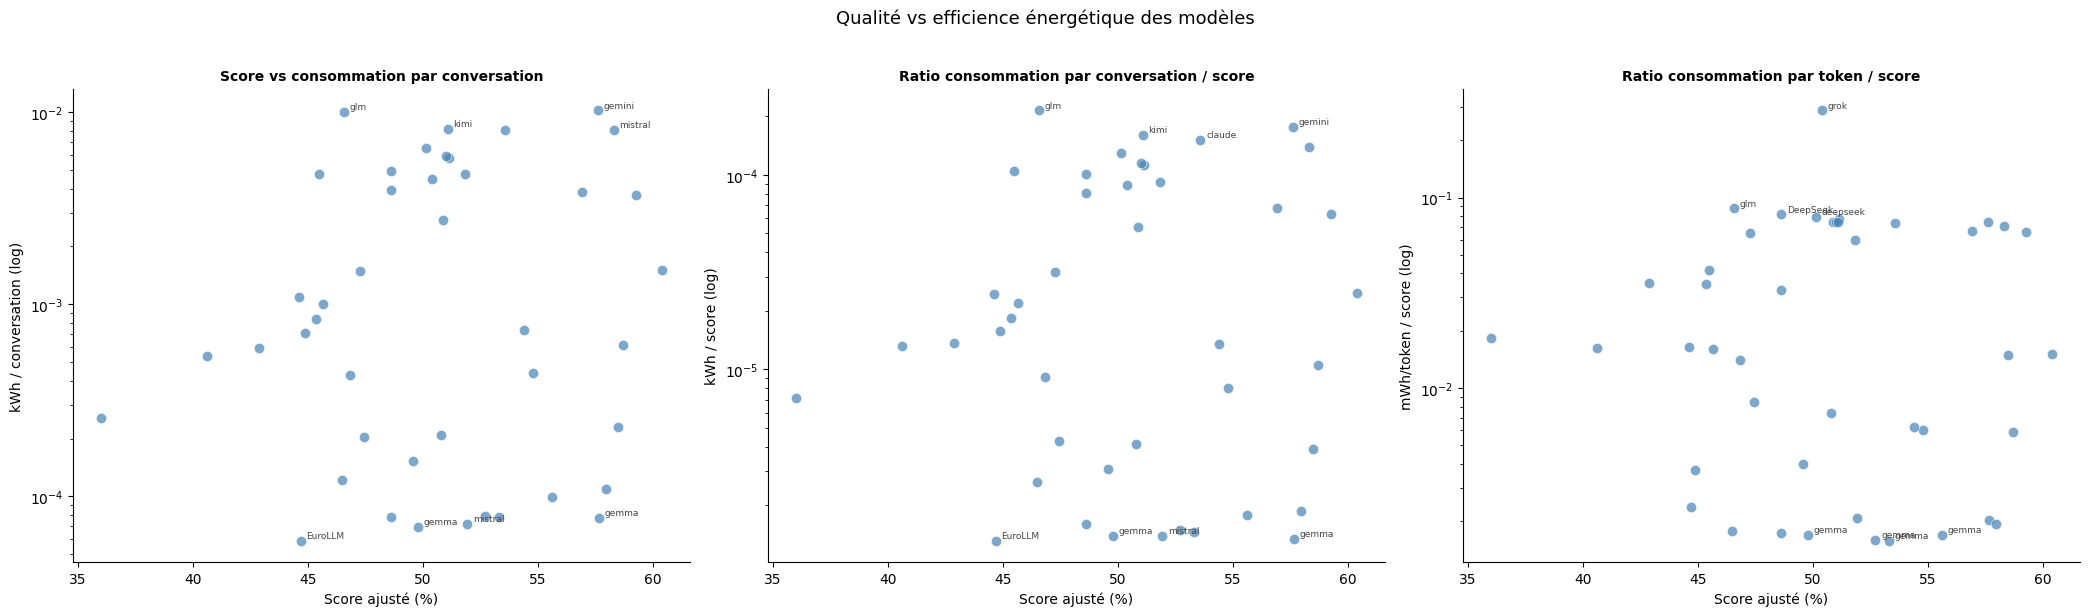

In [21]:
import matplotlib.pyplot as plt

croise_full = (
    croise[croise['model'] != 'olmo-3-32b-think']
    .merge(efficiency[['model', 'mwh_per_token']], on='model', how='left')
    .assign(
        ratio_conv=lambda df: df['avg_kwh'] / df['score'],
        ratio_token=lambda df: df['mwh_per_token'] / df['score'],
    )
)

def scatter_panel(ax, df, x, y, xlabel, ylabel, title):
    ax.scatter(df[x], df[y], alpha=0.7, s=55, color='steelblue', edgecolors='white', linewidth=0.5)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_yscale('log')  # échelle log pour lisibilité
    ax.spines[['top', 'right']].set_visible(False)
    for _, row in pd.concat([df.nsmallest(4, y), df.nlargest(4, y)]).drop_duplicates().iterrows():
        ax.annotate(
            row['model'].split('-')[0],
            (row[x], row[y]),
            fontsize=6.5, xytext=(4, 2),
            textcoords='offset points', color='#444'
        )

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

scatter_panel(
    axes[0], croise_full, 'score', 'avg_kwh',
    'Score ajusté (%)', 'kWh / conversation (log)',
    'Score vs consommation par conversation'
)

scatter_panel(
    axes[1], croise_full, 'score', 'ratio_conv',
    'Score ajusté (%)', 'kWh / score (log)',
    'Ratio consommation par conversation / score'
)

scatter_panel(
    axes[2], croise_full.dropna(subset=['ratio_token']), 'score', 'ratio_token',
    'Score ajusté (%)', 'mWh/token / score (log)',
    'Ratio consommation par token / score'
)

plt.suptitle('Qualité vs efficience énergétique des modèles', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


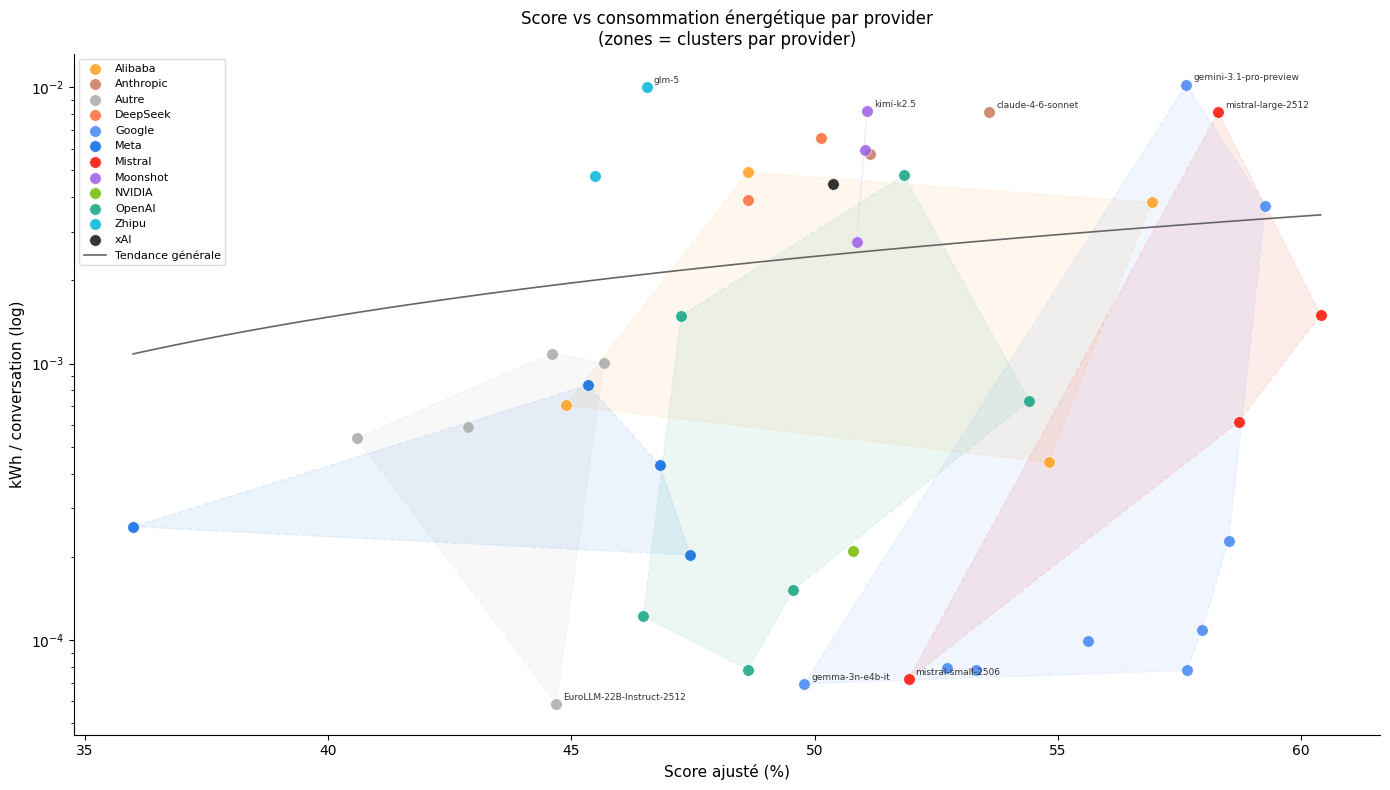

In [22]:
from scipy.spatial import ConvexHull
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import numpy as np

def get_provider(model):
    m = model.lower()
    if any(m.startswith(p) for p in ['gemini', 'gemma']):
        return 'Google'
    elif m.startswith('deepseek'):
        return 'DeepSeek'
    elif any(m.startswith(p) for p in ['mistral', 'magistral']):
        return 'Mistral'
    elif m.startswith('glm'):
        return 'Zhipu'
    elif m.startswith('qwen'):
        return 'Alibaba'
    elif m.startswith('grok'):
        return 'xAI'
    elif 'nemotron' in m:
        return 'NVIDIA'
    elif any(m.startswith(p) for p in ['llama', 'hermes']):
        return 'Meta'
    elif m.startswith('kimi'):
        return 'Moonshot'
    elif m.startswith('claude'):
        return 'Anthropic'
    elif m.startswith('gpt'):
        return 'OpenAI'
    else:
        return 'Autre'

provider_colors = {
    'Google':    '#4285F4',
    'DeepSeek':  '#FF6B35',
    'Mistral':   '#FA0F00',
    'Zhipu':     '#00B4D8',
    'Alibaba':   '#FF9F1C',
    'xAI':       '#111111',
    'NVIDIA':    '#76B900',
    'Meta':      '#0668E1',
    'Moonshot':  '#9B5DE5',
    'Anthropic': '#CC785C',
    'OpenAI':    '#10A37F',
    'Autre':     '#AAAAAA',
}

df = croise_full.copy()
df['provider'] = df['model'].apply(get_provider)

fig, ax = plt.subplots(figsize=(14, 8))

# Zones de cluster (convex hull) par provider
for provider, group in df.groupby('provider'):
    color = provider_colors.get(provider, '#AAAAAA')
    pts = group[['score', 'avg_kwh']].values
    if len(pts) >= 3:
        try:
            hull = ConvexHull(pts)
            poly = Polygon(
                pts[hull.vertices],
                closed=True,
                facecolor=color, alpha=0.08,
                edgecolor=color, linewidth=1.2, linestyle='--'
            )
            ax.add_patch(poly)
        except Exception:
            pass

# Points colorés par provider
for provider, group in df.groupby('provider'):
    color = provider_colors.get(provider, '#AAAAAA')
    ax.scatter(
        group['score'], group['avg_kwh'],
        color=color, s=70, alpha=0.85,
        edgecolors='white', linewidth=0.5,
        label=provider, zorder=3
    )

# Régression linéaire
x = df['score'].values
y = df['avg_kwh'].values
coef = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, np.polyval(coef, x_line), color='#666', linestyle='-', linewidth=1.2, label='Tendance générale')

# Labels des points extrêmes
for _, row in pd.concat([df.nlargest(5, 'avg_kwh'), df.nsmallest(3, 'avg_kwh')]).drop_duplicates().iterrows():
    ax.annotate(
        row['model'], (row['score'], row['avg_kwh']),
        fontsize=6.5, xytext=(5, 3),
        textcoords='offset points', color='#333'
    )

ax.set_yscale('log')
ax.set_xlabel('Score ajusté (%)', fontsize=11)
ax.set_ylabel('kWh / conversation (log)', fontsize=11)
ax.set_title('Score vs consommation énergétique par provider\n(zones = clusters par provider)', fontsize=12)
ax.legend(loc='upper left', fontsize=8, framealpha=0.7)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


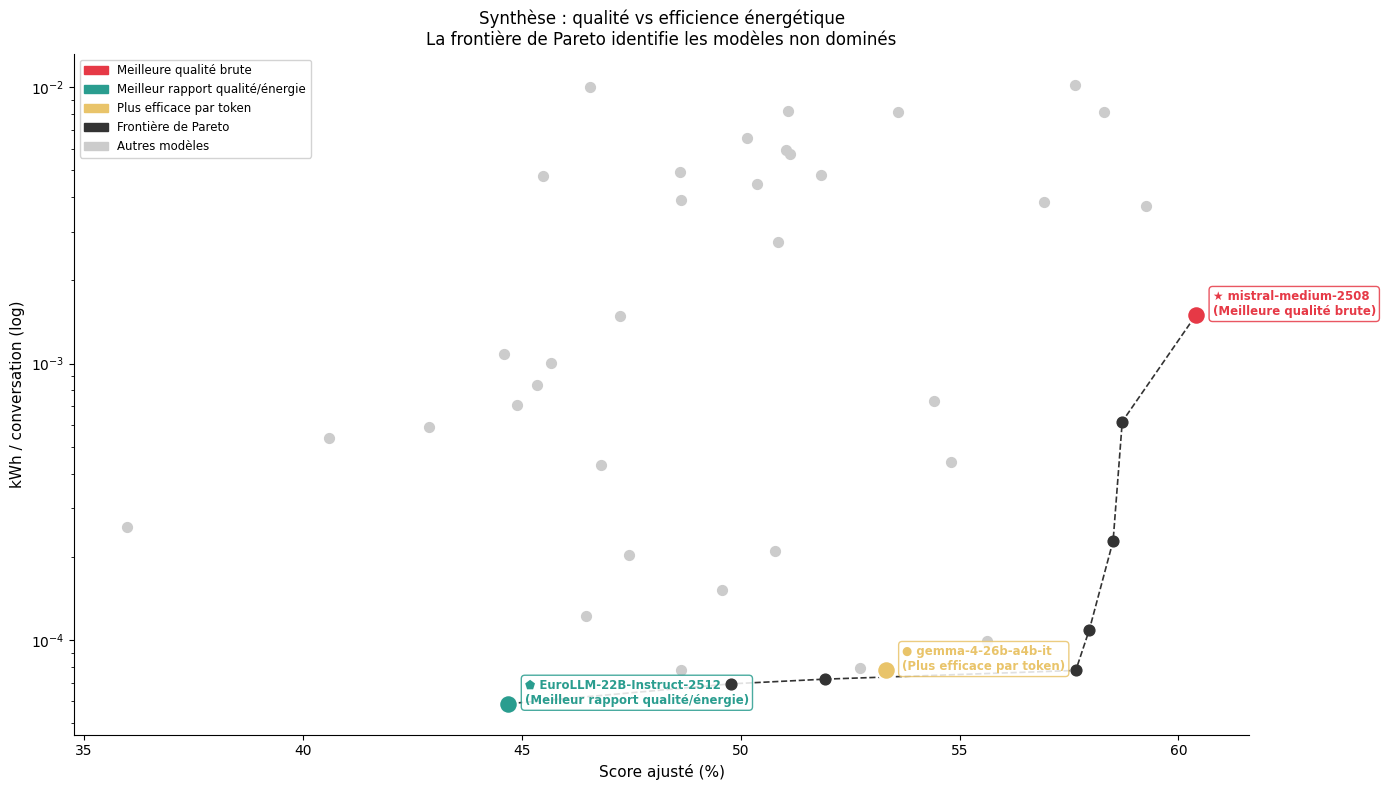

In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

df = croise_full.copy()
df['provider'] = df['model'].apply(get_provider)

# Frontière de Pareto : meilleur score POUR un niveau d'énergie donné
def pareto_frontier(df):
    df_sorted = df.sort_values('score', ascending=False)
    pareto, min_kwh = [], float('inf')
    for _, row in df_sorted.iterrows():
        if row['avg_kwh'] <= min_kwh:
            pareto.append(row.name)
            min_kwh = row['avg_kwh']
    return df.loc[pareto].sort_values('avg_kwh')

pareto = pareto_frontier(df)

# Trois profils champions
champion_qualite  = df.loc[df['score'].idxmax()]
champion_ratio    = df.loc[df['score_par_kwh'].idxmax()]
champion_token    = df.dropna(subset=['ratio_token']).loc[df.dropna(subset=['ratio_token'])['ratio_token'].idxmin()]

fig, ax = plt.subplots(figsize=(14, 8))

# Tous les modèles en gris clair
ax.scatter(df['score'], df['avg_kwh'], color='#CCCCCC', s=50, zorder=2, label='Autres modèles')

# Frontière de Pareto
ax.plot(pareto['score'], pareto['avg_kwh'], color='#333', linewidth=1.2,
        linestyle='--', zorder=3, label='Frontière de Pareto')
ax.scatter(pareto['score'], pareto['avg_kwh'], color='#333', s=60, zorder=4)

# Champions
champions = {
    'Meilleure qualité brute':        (champion_qualite,  '#E63946', '★'),
    'Meilleur rapport qualité/énergie': (champion_ratio,   '#2A9D8F', '⬟'),
    'Plus efficace par token':          (champion_token,   '#E9C46A', '●'),
}

for label, (champ, color, marker) in champions.items():
    ax.scatter(champ['score'], champ['avg_kwh'], color=color, s=180,
               zorder=5, edgecolors='white', linewidth=1.5)
    ax.annotate(
        f"{marker} {champ['model']}\n({label})",
        (champ['score'], champ['avg_kwh']),
        xytext=(12, 0), textcoords='offset points',
        fontsize=8.5, color=color, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color, alpha=0.85)
    )

# Légende manuelle pour les champions
legend_patches = [
    mpatches.Patch(color='#E63946', label='Meilleure qualité brute'),
    mpatches.Patch(color='#2A9D8F', label='Meilleur rapport qualité/énergie'),
    mpatches.Patch(color='#E9C46A', label='Plus efficace par token'),
    mpatches.Patch(color='#333',    label='Frontière de Pareto'),
    mpatches.Patch(color='#CCC',    label='Autres modèles'),
]
ax.legend(handles=legend_patches, loc='upper left', fontsize=8.5, framealpha=0.85)

ax.set_yscale('log')
ax.set_xlabel('Score ajusté (%)', fontsize=11)
ax.set_ylabel('kWh / conversation (log)', fontsize=11)
ax.set_title(
    'Synthèse : qualité vs efficience énergétique\n'
    'La frontière de Pareto identifie les modèles non dominés',
    fontsize=12
)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


**Rouge — meilleur score brut (sans considération énergétique)**
→ gemini-2.0-flash (score 64.7%) — leader du classement ajusté, mais consommation élevée

**Vert — meilleur score par kWh de conversation**
→ gemma-3-27b ou mistral-small-2603 — scores compétitifs (58%) pour une fraction de l'énergie des modèles frontières

**Jaune — meilleur score par mWh/token (efficience architecturale)**
→ gemma-3-4b / gemma-3-12b — les moins énergivores par token produit

### Dans quel contexte 
Pour un usage intensif en production → le ratio score/kWh favorise les gemma/mistral-small
Pour une tâche critique où la qualité prime → gemini-2.0-flash ou deepseek-v3
Pour une contrainte carbone stricte → les petits gemma dominent


In [ ]:
import plotly.graph_objects as go
import urllib.request, base64
from PIL import Image
from io import BytesIO

# Explode catégories depuis conv
conv_cat = (
    conv[['model_a_name', 'model_b_name', 'categories']]
    .assign(categories=lambda df: df['categories'].apply(list))
    .explode('categories')
    .dropna(subset=['categories'])
)
conv_cat = conv_cat[conv_cat['categories'].str.strip() != '']

nb_conv_cat = (
    pd.concat([
        conv_cat[['model_a_name', 'categories']].rename(columns={'model_a_name': 'model'}),
        conv_cat[['model_b_name', 'categories']].rename(columns={'model_b_name': 'model'}),
    ])
    .groupby(['categories', 'model']).size().reset_index(name='nb_conv')
    .query('nb_conv >= 30')
    .rename(columns={'categories': 'category'})
)

eligible = nb_conv_cat.merge(efficiency[['model', 'mwh_per_token']], on='model', how='inner')
eligible['provider'] = eligible['model'].apply(get_provider)

top5 = (
    eligible.sort_values('mwh_per_token')
    .groupby('category').head(5)
    .reset_index(drop=True)
)

categories = sorted(top5['category'].unique())

# Logos en base64 pour affichage Plotly
provider_logo_map = {
    'Google':   logo_urls.get('google', ''),
    'DeepSeek': logo_urls.get('deepseek', ''),
    'Mistral':  logo_urls.get('mistral', ''),
    'Zhipu':    logo_urls.get('zhipu', ''),
    'Alibaba':  logo_urls.get('qwen', ''),
    'xAI':      logo_urls.get('xai', ''),
    'NVIDIA':   logo_urls.get('nvidia', ''),
}

def url_to_b64(url):
    if not url: return ''
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=10) as r:
            img = Image.open(BytesIO(r.read())).convert('RGBA').resize((80, 80), Image.LANCZOS)
            buf = BytesIO()
            img.save(buf, format='PNG')
            return 'data:image/png;base64,' + base64.b64encode(buf.getvalue()).decode()
    except Exception as e:
        print(f'Logo non chargé ({url[:40]}...) : {e}')
        return ''

print('Chargement des logos...')
logo_b64 = {prov: url_to_b64(url) for prov, url in provider_logo_map.items()}
print('OK')

# Meilleur provider par catégorie (plus faible mwh_per_token)
best_prov_per_cat = (
    top5.sort_values('mwh_per_token').groupby('category').first()['provider'].to_dict()
)

# Construction du graphique Plotly
fig = go.Figure()

for cat in categories:
    df_cat = top5[top5['category'] == cat].sort_values('mwh_per_token')
    fig.add_trace(go.Bar(
        x=df_cat['mwh_per_token'],
        y=df_cat['model'],
        orientation='h',
        visible=(cat == categories[0]),
        marker_color=[provider_colors.get(p, '#AAAAAA') for p in df_cat['provider']],
        text=[f"{v:.4f} mWh/tok" for v in df_cat['mwh_per_token']],
        textposition='outside',
        hovertemplate='<b>%{y}</b><br>%{x:.4f} mWh/token<extra></extra>',
    ))

# Boutons dropdown + mise à jour du logo du meilleur provider
buttons = []
for i, cat in enumerate(categories):
    prov = best_prov_per_cat.get(cat, '')
    b64  = logo_b64.get(prov, '')
    buttons.append(dict(
        label=cat,
        method='update',
        args=[
            {'visible': [j == i for j in range(len(categories))]},
            {
                'title.text': f'Top 5 modèles économes (mWh/token) — {cat}',
                'images[0].source':  b64,
                'images[0].visible': bool(b64),
            }
        ]
    ))

init_prov = best_prov_per_cat.get(categories[0], '')
init_b64  = logo_b64.get(init_prov, '')

fig.update_layout(
    updatemenus=[dict(
        active=0, buttons=buttons,
        direction='down', showactive=True,
        x=0.0, y=1.22, xanchor='left', yanchor='top',
        bgcolor='white', bordercolor='#ccc',
    )],
    title=f'Top 5 modèles économes (mWh/token) — {categories[0]}',
    xaxis_title='mWh / token',
    yaxis=dict(autorange='reversed'),
    height=480,
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white',
    margin=dict(t=120),
    images=[dict(
        source=init_b64,
        xref='paper', yref='paper',
        x=1.0, y=1.25,
        sizex=0.12, sizey=0.12,
        xanchor='right', yanchor='top',
        visible=bool(init_b64),
        layer='above'
    )]
)
fig.show()


Chargement des logos...
OK


In [32]:
export_df(conv_cat)

Exporté : ../../data/processed/conv_cat.csv (29752 lignes)


In [30]:
# Consommation par requête = avg_kwh / avg_turns par modèle
# conv_turns représente le nombre de tours par conversation
import pandas as pd

avg_turns = (
    pd.concat([
        conv[['model_a_name', 'conv_turns']].rename(columns={'model_a_name': 'model'}),
        conv[['model_b_name', 'conv_turns']].rename(columns={'model_b_name': 'model'}),
    ])
    .groupby('model')['conv_turns']
    .mean()
    .reset_index()
    .rename(columns={'conv_turns': 'avg_turns'})
)

energy_par_requete = (
    energy[['model', 'avg_kwh', 'nb_conversations']]
    .merge(avg_turns, on='model', how='left')
    .assign(
        avg_turns=lambda df: df['avg_turns'].fillna(1.0).clip(lower=1.0),
        avg_kwh_per_req=lambda df: df['avg_kwh'] / df['avg_turns'],
    )
    .query('avg_kwh >= 0.00001')
    .sort_values('avg_kwh_per_req')
    .reset_index(drop=True)
)

print(f"{len(energy_par_requete)} modèles | avg_turns moyen : {energy_par_requete['avg_turns'].mean():.2f}")
energy_par_requete[['model', 'avg_kwh', 'avg_turns', 'avg_kwh_per_req']].head(10).style.format({
    'avg_kwh': '{:.5f}',
    'avg_turns': '{:.2f}',
    'avg_kwh_per_req': '{:.5f}',
})


43 modèles | avg_turns moyen : 1.17


,model,avg_kwh,avg_turns,avg_kwh_per_req
0,EuroLLM-22B-Instruct-2512,0.00006,1.00,0.00006
1,mistral-small-2506,0.00007,1.20,0.00006
2,gpt-5.4-nano,0.00008,1.28,0.00006
3,gemma-3n-e4b-it,0.00007,1.09,0.00006
4,gemma-3-4b,0.00008,1.18,0.00007
5,gemma-4-26b-a4b-it,0.00008,1.16,0.00007
6,gemma-4-31b-it,0.00008,1.07,0.00007
7,gemma-3-12b,0.00010,1.18,0.00008
8,gemma-3-27b,0.00011,1.07,0.00010
9,gpt-5.4-mini,0.00015,1.26,0.00012


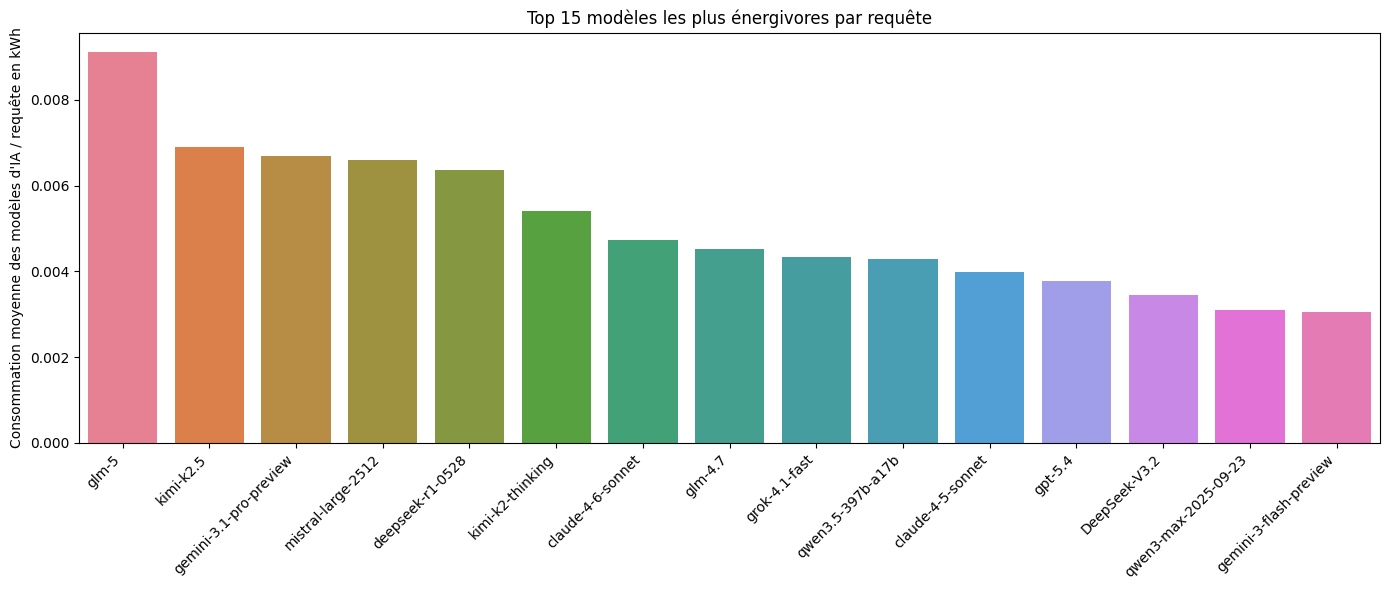

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

top = energy_par_requete.sort_values('avg_kwh_per_req', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(data=top, x='model', y='avg_kwh_per_req', hue='model', ax=ax)

ax.set_xlabel('')
ax.set_ylabel("Consommation moyenne des modèles d'IA / requête en kWh")
ax.set_title('Top 15 modèles les plus énergivores par requête')
ax.tick_params(axis='x', rotation=45)
for label in ax.get_xticklabels():
    label.set_ha('right')

plt.tight_layout()
plt.show()


Référence : 1 recherche Google ≈ 0.3 Wh
Modèle le plus sobre      : EuroLLM-22B-Instruct-2512 (0.20x)
Modèle le plus énergivore : glm-5 (30.35x)


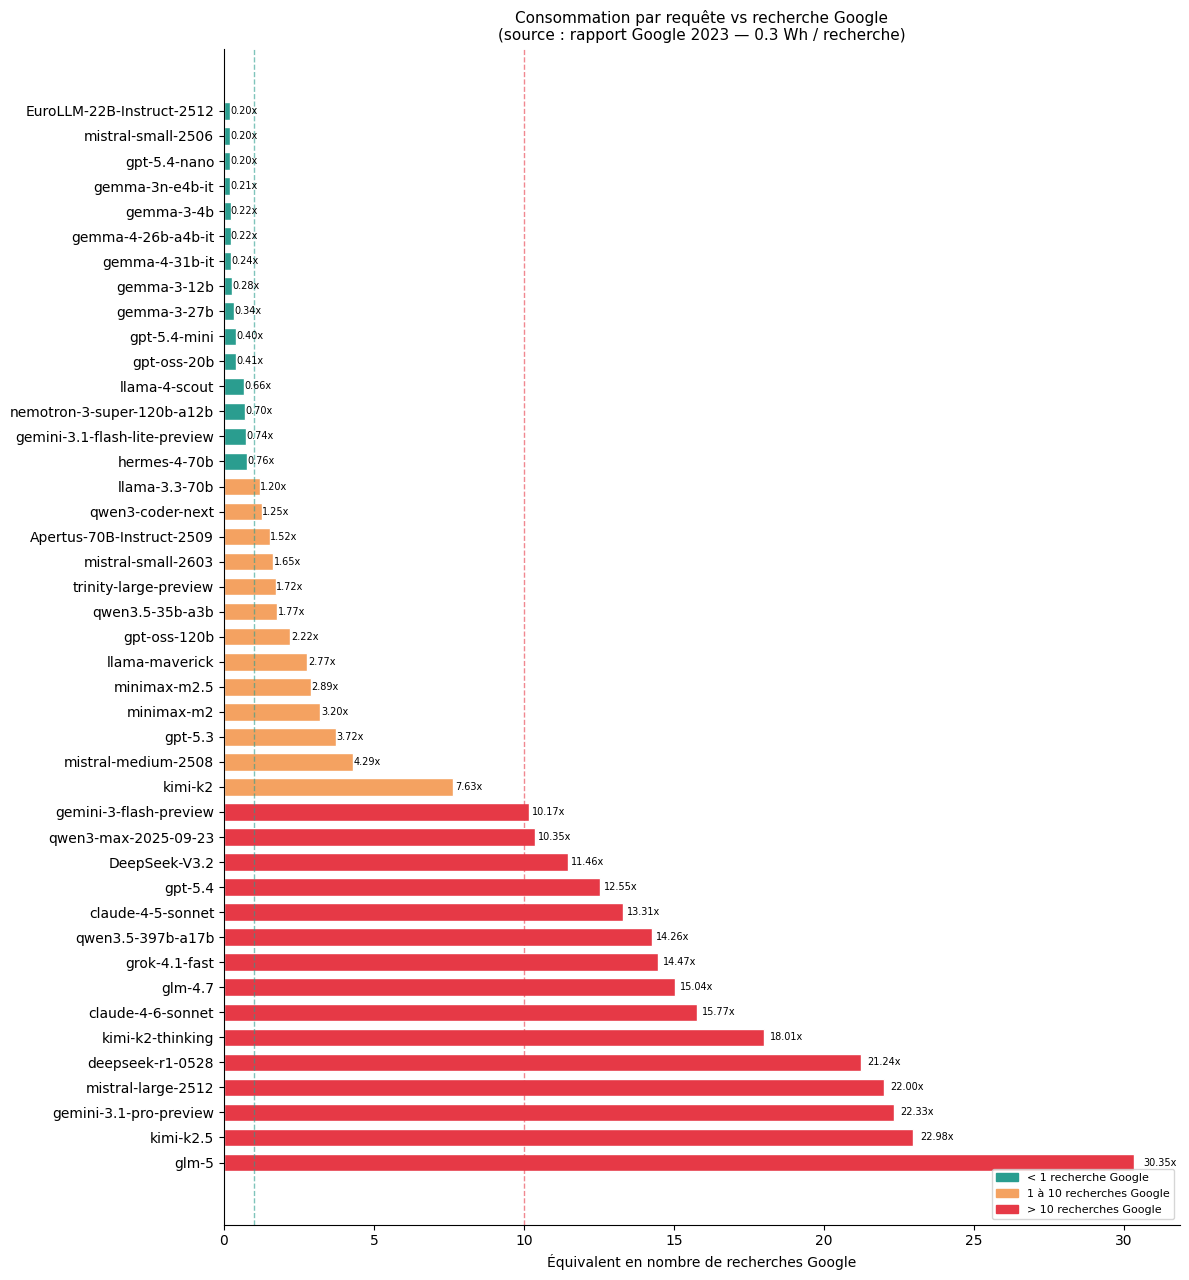

In [27]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

GOOGLE_SEARCH_KWH = 0.0003

comparison = (
    energy_par_requete[['model', 'avg_kwh_per_req', 'nb_conversations']]
    .assign(google_equivalent=lambda df: df['avg_kwh_per_req'] / GOOGLE_SEARCH_KWH)
    .sort_values('google_equivalent', ascending=True)
    .reset_index(drop=True)
)

comparison_sorted = comparison.copy()

print(f"Référence : 1 recherche Google ≈ {GOOGLE_SEARCH_KWH * 1000:.1f} Wh")
print(f"Modèle le plus sobre      : {comparison_sorted.iloc[0]['model']} ({comparison_sorted.iloc[0]['google_equivalent']:.2f}x)")
print(f"Modèle le plus énergivore : {comparison_sorted.iloc[-1]['model']} ({comparison_sorted.iloc[-1]['google_equivalent']:.2f}x)")

def get_color(val):
    if val < 1:   return '#2A9D8F'
    elif val < 10: return '#F4A261'
    else:          return '#E63946'

colors = [get_color(v) for v in comparison['google_equivalent']]

fig, ax = plt.subplots(figsize=(12, max(8, len(comparison) * 0.3)))
ax.barh(comparison['model'], comparison['google_equivalent'],
        color=colors, edgecolor='white', height=0.7)
ax.invert_yaxis()

ax.axvline(1,  color='#2A9D8F', linestyle='--', linewidth=1, alpha=0.6)
ax.axvline(10, color='#E63946', linestyle='--', linewidth=1, alpha=0.6)

for i, (_, row) in enumerate(comparison.iterrows()):
    ax.text(row['google_equivalent'] * 1.01, i,
            f"{row['google_equivalent']:.2f}x", va='center', fontsize=7)

legend_patches = [
    mpatches.Patch(color='#2A9D8F', label='< 1 recherche Google'),
    mpatches.Patch(color='#F4A261', label='1 à 10 recherches Google'),
    mpatches.Patch(color='#E63946', label='> 10 recherches Google'),
]
ax.legend(handles=legend_patches, fontsize=8, loc='lower right')
ax.set_xlabel('Équivalent en nombre de recherches Google', fontsize=10)
ax.set_title('Consommation par requête vs recherche Google\n(source : rapport Google 2023 — 0.3 Wh / recherche)', fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


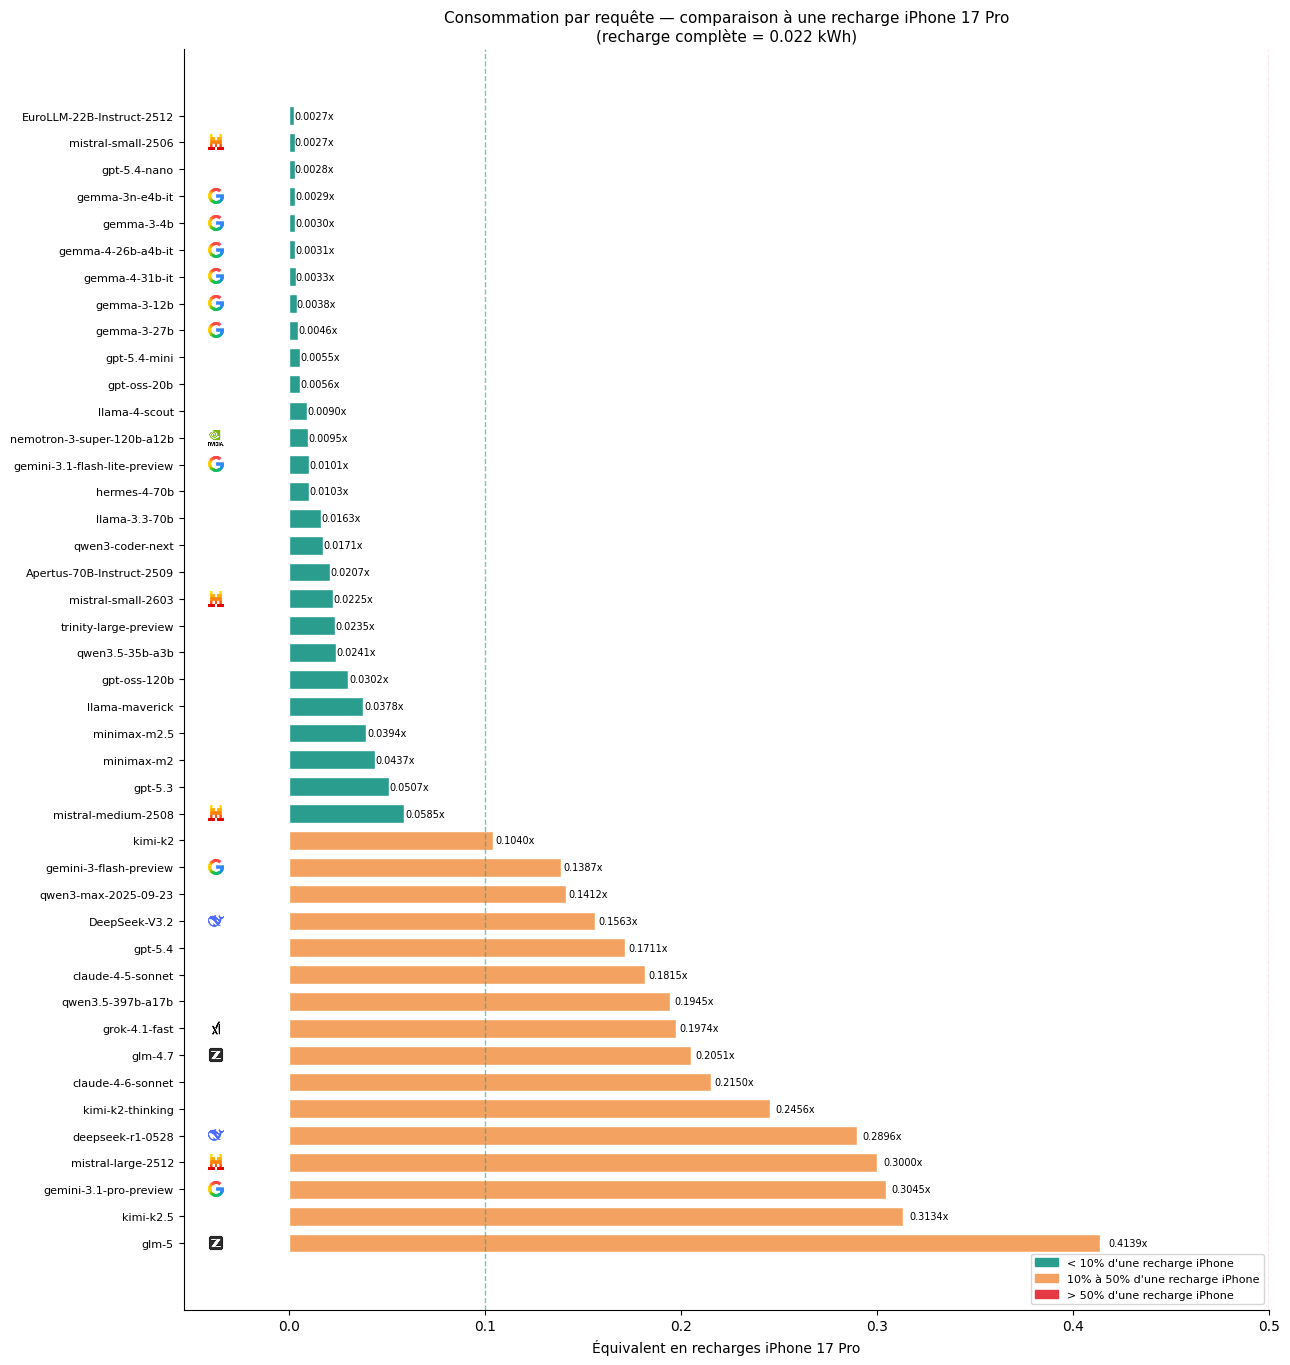

In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

IPHONE_KWH = 0.022  # recharge complète iPhone 17 Pro

iphone_comp = (
    energy_par_requete[['model', 'avg_kwh_per_req']]
    .assign(
        iphone_equivalent=lambda df: df['avg_kwh_per_req'] / IPHONE_KWH,
        provider=lambda df: df['model'].apply(get_provider)
    )
    .sort_values('iphone_equivalent', ascending=True)
    .reset_index(drop=True)
)

def get_color_iphone(val):
    if val < 0.1:   return '#2A9D8F'
    elif val < 0.5: return '#F4A261'
    else:           return '#E63946'

colors = [get_color_iphone(v) for v in iphone_comp['iphone_equivalent']]

fig, ax = plt.subplots(figsize=(13, max(8, len(iphone_comp) * 0.32)))

max_val = iphone_comp['iphone_equivalent'].max()
logo_x  = -max_val * 0.09

ax.barh(range(len(iphone_comp)), iphone_comp['iphone_equivalent'],
        color=colors, edgecolor='white', height=0.7)
ax.invert_yaxis()

ax.set_yticks(range(len(iphone_comp)))
ax.set_yticklabels(iphone_comp['model'].values, fontsize=8)

# Logos à gauche de chaque modèle
for i, (_, row) in enumerate(iphone_comp.iterrows()):
    prov_key = row['provider'].lower()
    if prov_key in logo_imgs:
        imagebox = OffsetImage(logo_imgs[prov_key], zoom=0.28)
        ab = AnnotationBbox(imagebox, (logo_x, i), xycoords='data', frameon=False, pad=0)
        ax.add_artist(ab)

# Annotations valeurs
for i, (_, row) in enumerate(iphone_comp.iterrows()):
    ax.text(row['iphone_equivalent'] * 1.01, i,
            f"{row['iphone_equivalent']:.4f}x", va='center', fontsize=7)

ax.axvline(0.1, color='#2A9D8F', linestyle='--', linewidth=1, alpha=0.6)
ax.axvline(0.5, color='#E63946', linestyle='--', linewidth=1, alpha=0.6)

ax.set_xlim(logo_x - max_val * 0.04, max_val * 1.18)
ax.set_xticks([t for t in ax.get_xticks() if t >= 0])

legend_patches = [
    mpatches.Patch(color='#2A9D8F', label="< 10% d'une recharge iPhone"),
    mpatches.Patch(color='#F4A261', label="10% à 50% d'une recharge iPhone"),
    mpatches.Patch(color='#E63946', label="> 50% d'une recharge iPhone"),
]
ax.legend(handles=legend_patches, fontsize=8, loc='lower right')

ax.set_xlabel('Équivalent en recharges iPhone 17 Pro', fontsize=10)
ax.set_title(
    'Consommation par requête — comparaison à une recharge iPhone 17 Pro\n'
    '(recharge complète = 0.022 kWh)',
    fontsize=11
)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


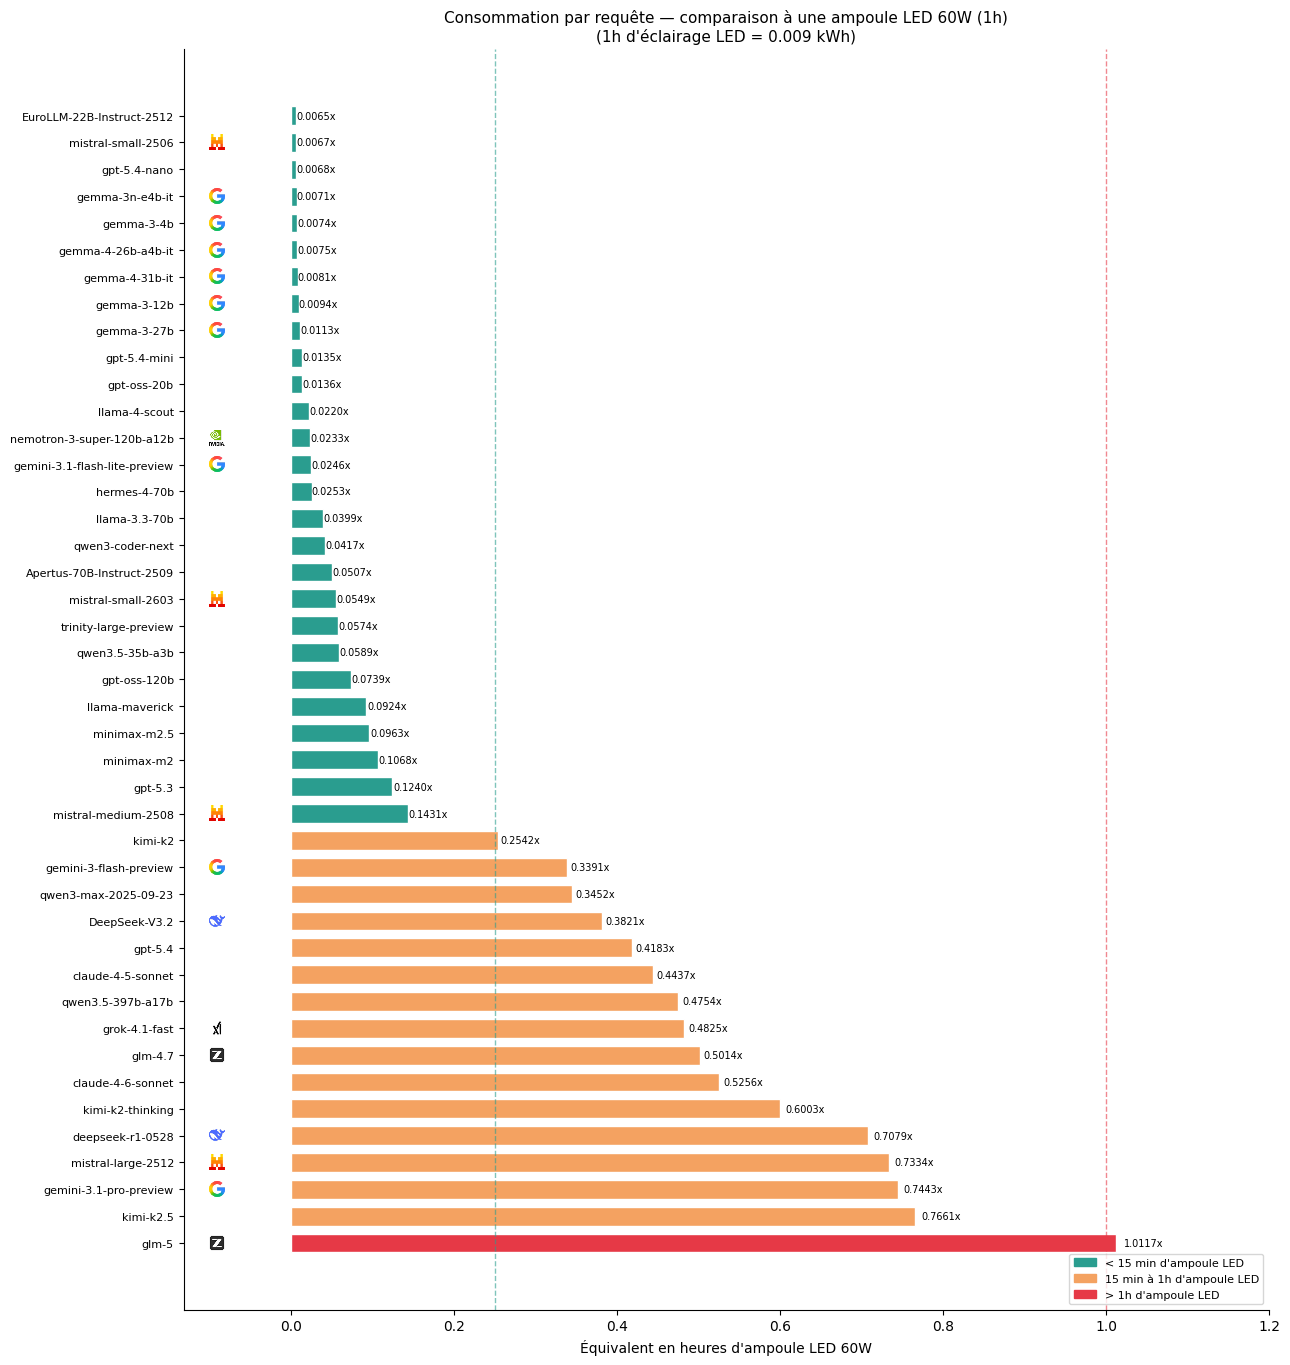

In [95]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

LED_KWH = 0.009  # ampoule LED 60W allumée 1 heure

led_comp = (
    energy_par_requete[['model', 'avg_kwh_per_req']]
    .assign(
        led_equivalent=lambda df: df['avg_kwh_per_req'] / LED_KWH,
        provider=lambda df: df['model'].apply(get_provider)
    )
    .sort_values('led_equivalent', ascending=True)
    .reset_index(drop=True)
)

def get_color_led(val):
    if val < 0.25:  return '#2A9D8F'
    elif val < 1.0: return '#F4A261'
    else:           return '#E63946'

colors = [get_color_led(v) for v in led_comp['led_equivalent']]

fig, ax = plt.subplots(figsize=(13, max(8, len(led_comp) * 0.32)))

max_val = led_comp['led_equivalent'].max()
logo_x  = -max_val * 0.09

ax.barh(range(len(led_comp)), led_comp['led_equivalent'],
        color=colors, edgecolor='white', height=0.7)
ax.invert_yaxis()

ax.set_yticks(range(len(led_comp)))
ax.set_yticklabels(led_comp['model'].values, fontsize=8)

for i, (_, row) in enumerate(led_comp.iterrows()):
    prov_key = row['provider'].lower()
    if prov_key in logo_imgs:
        imagebox = OffsetImage(logo_imgs[prov_key], zoom=0.28)
        ab = AnnotationBbox(imagebox, (logo_x, i), xycoords='data', frameon=False, pad=0)
        ax.add_artist(ab)

for i, (_, row) in enumerate(led_comp.iterrows()):
    ax.text(row['led_equivalent'] * 1.01, i,
            f"{row['led_equivalent']:.4f}x", va='center', fontsize=7)

ax.axvline(0.25, color='#2A9D8F', linestyle='--', linewidth=1, alpha=0.6)
ax.axvline(1.0,  color='#E63946', linestyle='--', linewidth=1, alpha=0.6)

ax.set_xlim(logo_x - max_val * 0.04, max_val * 1.18)
ax.set_xticks([t for t in ax.get_xticks() if t >= 0])

legend_patches = [
    mpatches.Patch(color='#2A9D8F', label='< 15 min d\'ampoule LED'),
    mpatches.Patch(color='#F4A261', label='15 min à 1h d\'ampoule LED'),
    mpatches.Patch(color='#E63946', label='> 1h d\'ampoule LED'),
]
ax.legend(handles=legend_patches, fontsize=8, loc='lower right')

ax.set_xlabel("Équivalent en heures d'ampoule LED 60W", fontsize=10)
ax.set_title(
    "Consommation par requête — comparaison à une ampoule LED 60W (1h)\n"
    "(1h d'éclairage LED = 0.009 kWh)",
    fontsize=11
)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


In [29]:
import plotly.graph_objects as go

REFERENCES = {
    'Recherche Google':       {'kwh': 0.0003, 'low': 1,    'high': 10,  'label': '1 recherche Google'},
    'Recharge iPhone 17 Pro': {'kwh': 0.022,  'low': 0.1,  'high': 0.5, 'label': '1 recharge iPhone'},
    'Ampoule LED 60W (1h)':   {'kwh': 0.009,  'low': 0.25, 'high': 1.0, 'label': "1h d'ampoule LED"},
}

def threshold_color(val, low, high):
    if val < low:    return '#2A9D8F'
    elif val < high: return '#F4A261'
    else:            return '#E63946'

fig = go.Figure()
ref_names = list(REFERENCES.keys())

for ref_name, cfg in REFERENCES.items():
    df = (
        energy_par_requete[['model', 'avg_kwh_per_req']]
        .assign(equivalent=lambda d: d['avg_kwh_per_req'] / cfg['kwh'])
        .sort_values('equivalent', ascending=True)
        .reset_index(drop=True)
    )
    fig.add_trace(go.Bar(
        x=df['equivalent'],
        y=df['model'],
        orientation='h',
        name=ref_name,
        visible=(ref_name == ref_names[0]),
        marker_color=[threshold_color(v, cfg['low'], cfg['high']) for v in df['equivalent']],
        text=[f"{v:.4f}x" for v in df['equivalent']],
        textposition='outside',
        hovertemplate=(
            '<b>%{y}</b><br>'
            f'%{{x:.4f}}× {cfg["label"]}'
            '<extra></extra>'
        ),
    ))

# Définition des seuils de légende par référence
legend_labels = {
    'Recherche Google':       ['< 1 recherche Google', '1 à 10 recherches Google', '> 10 recherches Google'],
    'Recharge iPhone 17 Pro': ["< 10% d'une recharge iPhone", "10% à 50% d'une recharge", "> 50% d'une recharge"],
    'Ampoule LED 60W (1h)':   ["< 15 min d'ampoule LED", "15 min à 1h d'ampoule LED", "> 1h d'ampoule LED"],
}

def make_legend_annotation(labels):
    return (
        f"<span style='color:#2A9D8F'>■</span> {labels[0]}&nbsp;&nbsp;"
        f"<span style='color:#F4A261'>■</span> {labels[1]}&nbsp;&nbsp;"
        f"<span style='color:#E63946'>■</span> {labels[2]}"
    )

# Boutons dropdown
buttons = []
for i, ref_name in enumerate(ref_names):
    buttons.append(dict(
        label=ref_name,
        method='update',
        args=[
            {'visible': [j == i for j in range(len(ref_names))]},
            {
                'title.text': f'Consommation par requête — comparaison : {ref_name}',
                'annotations[0].text': make_legend_annotation(legend_labels[ref_name]),
            }
        ]
    ))

fig.update_layout(
    updatemenus=[dict(
        active=0,
        buttons=buttons,
        direction='down',
        showactive=True,
        x=0.0, y=1.12,
        xanchor='left', yanchor='top',
        bgcolor='white', bordercolor='#ccc',
    )],
    title=f'Consommation par requête — comparaison : {ref_names[0]}',
    xaxis_title='Équivalent (multiple de la référence)',
    yaxis=dict(autorange='reversed'),
    height=max(500, len(energy_par_requete) * 22),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white',
    margin=dict(t=100, l=250),
    annotations=[dict(
        text=make_legend_annotation(legend_labels[ref_names[0]]),
        xref='paper', yref='paper',
        x=0.0, y=1.06,
        showarrow=False,
        font=dict(size=11),
        align='left',
    )]
)
fig.show()


In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML

GOOGLE_KWH = 0.0003
IPHONE_KWH = 0.022
LED_KWH    = 0.009

def fmt_led(kwh):
    s = kwh / LED_KWH * 3600
    if s < 60:   return f"{s:.0f} secondes"
    elif s < 3600: return f"{s/60:.1f} minutes"
    else:          return f"{s/3600:.2f} heures"

def fmt_google(kwh):
    g = kwh / GOOGLE_KWH
    return f"{g*100:.1f}% d'une recherche" if g < 1 else f"{g:.2f} recherches"

def fmt_iphone(kwh):
    return f"{kwh / IPHONE_KWH * 100:.2f}% d'une recharge"

# Logo Google en base64 si disponible
google_img = (
    f"<img src='{logo_b64.get('Google', '')}' style='height:32px;vertical-align:middle;'>"
    if 'logo_b64' in dir() and logo_b64.get('Google') else '🔍'
)

def make_card(icon, label, value, color, bg):
    return f"""
    <div style='
        background:{bg}; border-top:4px solid {color};
        border-radius:12px; padding:20px 18px;
        min-width:180px; flex:1;
        box-shadow:0 2px 8px rgba(0,0,0,0.07);
        font-family:sans-serif; text-align:center;
    '>
        <div style='font-size:36px; margin-bottom:10px;'>{icon}</div>
        <div style='font-size:11px; color:#888; text-transform:uppercase; letter-spacing:.05em; margin-bottom:6px;'>{label}</div>
        <div style='font-size:17px; font-weight:700; color:{color};'>{value}</div>
    </div>
    """

models = sorted(energy_par_requete['model'].tolist())
dropdown = widgets.Dropdown(
    options=models,
    description='Modèle :',
    layout=widgets.Layout(width='350px')
)
output = widgets.Output()

def update(change):
    model = change['new']
    row   = energy_par_requete[energy_par_requete['model'] == model].iloc[0]
    kwh   = row['avg_kwh_per_req']

    cards = (
        make_card('💡', 'Ampoule LED 60W',    fmt_led(kwh),    '#F4A261', '#fff8f0')
        + make_card(google_img, 'Recherche Google', fmt_google(kwh), '#4285F4', '#f0f4ff')
        + make_card('🔋', 'Recharge iPhone',   fmt_iphone(kwh), '#2A9D8F', '#f0faf8')
    )

    html = f"""
    <div style='padding:8px 0 16px 0; font-family:sans-serif;'>
        <div style='font-size:13px; color:#888; margin-bottom:12px;'>
            Coût énergétique de <strong>1 requête</strong> avec <strong>{model}</strong>
        </div>
        <div style='display:flex; gap:16px;'>{cards}</div>
    </div>
    """

    output.clear_output(wait=True)
    with output:
        display(HTML(html))

dropdown.observe(update, names='value')
update({'new': models[0]})
display(dropdown, output)


Dropdown(description='Modèle :', layout=Layout(width='350px'), options=('Apertus-70B-Instruct-2509', 'DeepSeek…

Output()

In [33]:
export_df(efficiency)

Exporté : ../../data/processed/efficiency.csv (44 lignes)


In [34]:
export_df(energy_par_requete)

Exporté : ../../data/processed/energy_par_requete.csv (43 lignes)


In [37]:
metadata = pd.DataFrame([{
    "nb_conversations_uniques": conv["conversation_pair_id"].nunique(),
    "nb_modeles_classement":    len(classement_score_ajuste),
    "nb_modeles_energie":       len(energy.query("avg_kwh >= 0.00001")),
}])

metadata


,nb_conversations_uniques,nb_modeles_classement,nb_modeles_energie
0,18690,104,43


In [ ]:
# ─────────────────────────────────────────────────────────────────
# Création de energy_global.csv
# Fusion de 3 dataframes déjà en mémoire :
#   - energy              → avg_kwh + nb_conversations par modèle
#   - energy_par_requete  → avg_turns + avg_kwh_per_req par modèle
#   - efficiency          → total_tokens + kwh_per_token + mwh_per_token
# ─────────────────────────────────────────────────────────────────

# Vérification : avg_kwh identique entre energy et energy_par_requete
check = energy.merge(energy_par_requete[['model', 'avg_kwh']], on='model', suffixes=('_e', '_enr'))
assert (check['avg_kwh_e'] - check['avg_kwh_enr']).abs().max() < 1e-10, 'avg_kwh incohérent !'
print(f'avg_kwh cohérent entre les deux sources ✓')
print(f'energy : {len(energy)} modèles | energy_par_requete : {len(energy_par_requete)} | efficiency : {len(efficiency)}')

# Fusion : energy comme base (44 modèles)
# LEFT JOIN avec energy_par_requete → 43 modèles ont avg_turns et avg_kwh_per_req (olmo absent)
# LEFT JOIN avec efficiency         → même 44 modèles, colonnes token
energy_global = (
    energy[['model', 'avg_kwh', 'nb_conversations']]
    .merge(energy_par_requete[['model', 'avg_turns', 'avg_kwh_per_req']], on='model', how='left')
    .merge(efficiency[['model', 'total_tokens', 'kwh_per_token', 'mwh_per_token']], on='model', how='left')
)

print(f'energy_global : {energy_global.shape[0]} modèles × {energy_global.shape[1]} colonnes')
print(f'Colonnes : {list(energy_global.columns)}')
print(f'\nModèle avec avg_turns NaN (absent de energy_par_requete) :')
print(energy_global[energy_global['avg_turns'].isna()][['model', 'avg_kwh']].to_string())

export_df(energy_global)
energy_global.head(5)


In [ ]:
# Régénération de ranking_per_cat depuis conv_cat (déjà en mémoire)
# conv_cat contient : model_a_name, model_b_name, categories (explodé)

# Compte de conversations par modèle et catégorie
nb_conv_cat = (
    pd.concat([
        conv_cat[['model_a_name', 'categories']].rename(columns={'model_a_name': 'model'}),
        conv_cat[['model_b_name', 'categories']].rename(columns={'model_b_name': 'model'}),
    ])
    .groupby(['model', 'categories'])
    .size()
    .reset_index(name='nb_conv_cat')
    .query('nb_conv_cat >= 30')
)

print(f'{nb_conv_cat["categories"].nunique()} catégories | {nb_conv_cat["model"].nunique()} modèles')

# Fusion avec energy_global pour récupérer les métriques énergétiques
ranking_per_cat = (
    nb_conv_cat
    .merge(
        energy_global[['model', 'mwh_per_token', 'avg_kwh', 'avg_kwh_per_req']],
        on='model', how='inner'
    )
    .dropna(subset=['mwh_per_token'])
    .sort_values(['categories', 'mwh_per_token'])
    .reset_index(drop=True)
)

print(f'ranking_per_cat : {ranking_per_cat.shape[0]} lignes × {ranking_per_cat.shape[1]} colonnes')

export_df(ranking_per_cat)
ranking_per_cat.head()
